<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_HomomorphicEncryptionDefence_Wang2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homomorphic data encryption as a defence for a quantum neural network: Wang et al. (2023) step by step

This notebook re-implements, runs and critically checks the experiments of

> Ellen Wang, Helena Chaine, Xiaodi Wang, Avi Ray and Tyler Wooldridge,
> "Defending Quantum Neural Networks against Adversarial Attacks with Homomorphic Data Encryption",
> 2023 International Conference on Computational Science and Computational Intelligence (CSCI), IEEE, 2023,
> DOI [10.1109/CSCI62032.2023.00138](https://doi.org/10.1109/csci62032.2023.00138).

**What the notebook does.** It downloads MNIST, builds a quantum neural network (PennyLane, 8 qubits) and the Keras-tutorial convolutional
network the paper uses as benchmark, generates Fast Gradient Sign (FGSM) adversarial examples, encrypts data with keyed per-pixel ciphers,
and repeats the paper's three trials (original / attacked / attacked + encrypted) for both networks. It then goes beyond the paper with the tests
the paper does not contain: a no-encryption control, a fixed deployed model attacked at test time (evasion), and **adaptive attackers** that know the
encryption (key-aware gradients, a two-query chosen-plaintext key recovery, and a key-less attacker who only knows the cipher family).
A real toy GSW homomorphic scheme is implemented and tested so that the reader can see why GSW ciphertexts cannot be what a network was trained on.

**How to run.** Open in Google Colab (CPU runtime is enough) and choose *Runtime -> Run all*. With `FAST_MODE = True` (default in the cell below)
the run takes about 10 minutes; set `FAST_MODE = False` for the full budgets described in the configuration cell.
MNIST is public; a Hugging Face token (Colab *Secrets* -> `HF_TOKEN`) is only read if present and is never printed.

**What you get at the end.** Accuracy tables for the paper's six numbers, training curves in the style of the paper's Figures 4-9, robustness-versus-epsilon
curves for four attackers, a label-leakage test of the FGSM data, classical baselines on identical inputs, the circuit that is executed (with and without the
encryption layer) and a per-claim verdict table.

## The paper in one page

**Problem.** Quantum neural networks (QNNs) are vulnerable to adversarial examples. The authors ask whether *homomorphic encryption of the data* protects a QNN.

**Idea.** Encrypt the input with a fully homomorphic lattice scheme (the GSW scheme, implemented in Python by Hedglin et al. after Minelli) so that the network
sees ciphertext, not the plain image.

**Method.** (i) A QNN built from PennyLane's angle embedding and quantum layers wrapped as Keras layers, trained with SGD and the mean absolute error; (ii) the Keras
`mnist_convnet` tutorial CNN as a classical benchmark; (iii) FGSM from the TensorFlow tutorial with epsilon 6 (CNN) and 75 (QNN); (iv) GSW encryption.

**Data.** MNIST, 28 x 28 images scaled to (-1, 1); batch size 128, 15 epochs. Three trials per network: original data (control); data after the FGSM attack;
attacked data that was also homomorphically encrypted. Training and validation curves are plotted for each trial (Figures 4-9).

**Claims (accuracy, Section III).**

| Trial | QNN | CNN |
|---|---|---|
| original (control) | 0.9247 | 0.9926 |
| FGSM-attacked | 0.8406 | 0.7734 |
| attacked + encrypted | **0.9728** | 0.3814 |

The authors conclude that the encryption "defends" the QNN (even above the control), that the QNN is far more noise-tolerant than the CNN (epsilon had to be 75 instead of 6,
and accuracy stayed above 95% for epsilon up to 60 in several trials), and that this shows a quantum advantage. They state as a limitation that they could not
encrypt the network itself, and that the data was encrypted before the attack was introduced in one place and after it in another.

### What follows the paper and what had to be chosen

The paper does not give circuit sizes, the way images enter the QNN, the optimiser settings, the encryption parameters or how a GSW ciphertext is turned into a network input.
Everything below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MNIST, 60,000 images, scaled to (-1, 1) | MNIST (HF `ylecun/mnist`), a random subset (see configuration), scaled to (-1, 1) |
| Quantum network | PennyLane angle embedding + quantum layers as Keras layers | `AngleEmbedding` (RX) + `StronglyEntanglingLayers`, **8 qubits, 3 layers**, `<Z_i>` read-out; a trainable classical `Linear(784 -> 8)` (PCA-initialised) in front and `Linear(8 -> 10)` behind (not specified) |
| Qubit simulation | not stated | exact state-vector; a fast batched torch simulator that is asserted equal to the PennyLane QNode (values and gradients) |
| Training | SGD, mean absolute error, batch 128, 15 epochs | batch 128, 15 epochs (4 in FAST); **Adam + cross-entropy**, because the paper-literal SGD + MAE is shown in section 9 not to train within this budget |
| Classical network | Keras `mnist_convnet` | the same layers in PyTorch (Conv32, Conv64, dropout 0.5, dense), Adam |
| FGSM | TF tutorial, epsilon 6 (CNN), 75 (QNN) | the same epsilons, **not clipped** (the only reading under which epsilon 75 on a (-1, 1) image is meaningful); gradient of the cross-entropy; true labels |
| Attack protocol | a new network is trained and validated on each transformed data set (Figures 4-9) | reproduced exactly (experiment A), then a standard evasion protocol with a fixed deployed model (experiment B) |
| Encryption | GSW fully homomorphic scheme (Hedglin / Minelli) | a toy GSW is implemented (section 3); the data transform used in the trials is a **deterministic keyed per-pixel cipher** (modular over Z_257, or affine) because GSW output cannot be a fixed-size learnable input |
| Order of attack and encryption | encrypt(attack(x)) in the trial description | the same (trial 3); in experiment B the cipher is part of the model and the attacker sees plain images |
| Adaptive attacker, no-encryption control | absent | added (experiment B) |
| Seeds | "three trials", averaged | `SEEDS` (1 in FAST, 2 in the full run); mean and standard deviation reported |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch.
# The pip line runs on Colab (or wherever PennyLane / huggingface_hub are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in ("pennylane", "huggingface_hub", "torch", "pyarrow")):
    %pip install -q "pennylane==0.45.1" "huggingface_hub" "pyarrow" "pillow"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Required packages already available - nothing to install.")

Required packages already available - nothing to install.


In [2]:
# ----------------------------- CONFIGURATION: every tunable constant lives here -----------------------------
SEED = 42                      # global seed (numpy / torch / python); per-run seeds below are derived from it
FAST_MODE = False              # True: ~10 minute class demo. False: full budgets (see the table in the next markdown cell)

if FAST_MODE:
    N_TRAIN, N_TEST = 600, 300     # MNIST images drawn from the official train / test split
    EPOCHS          = 4            # paper: 15
    SEEDS           = [0]          # independent repetitions (initialisation, shuffling, encryption key)
    N_ATT           = 100          # test images attacked in the evasion experiments
    PGD_STEPS       = 5
else:
    N_TRAIN, N_TEST = 2000, 1000
    EPOCHS          = 15           # as in the paper
    SEEDS           = [0, 1]
    N_ATT           = 200
    PGD_STEPS       = 10

BATCH         = 128                # as in the paper
NQ, N_LAYERS  = 8, 3               # CHOICE: 8 qubits, 3 StronglyEntanglingLayers (paper gives no sizes)
LR_QNN, LR_FRONT = 0.03, 3e-4      # CHOICE: Adam learning rates (circuit + head / classical 784->8 front layer)
EPS_PAPER     = {"QNN": 75.0, "CNN": 6.0}     # epsilon values quoted by the paper (pixel scale (-1, 1), NOT clipped)
EPS_STD       = [0.05, 0.1, 0.2]   # evasion experiments: standard epsilons on the (-1, 1) pixel scale, clipped to (-1, 1)
EPS_LARGE     = [6.0, 30.0, 75.0]  # evasion experiments: paper-scale epsilons, FGSM only, not clipped
CIPHER_KINDS  = ["modular", "affine"]  # the two deterministic encryption layers tested (see section 2)
Q_MOD         = 257                # modulus of the modular cipher (prime, > 255 pixel levels)
DATA_DIR      = "mnist_cache"      # downloads are cached here
IBM_TOKEN     = ""                 # not used: every circuit runs on exact simulators
paper_budget_note = "FULL budgets: N_TRAIN=2000, N_TEST=1000, EPOCHS=15, SEEDS=[0,1], N_ATT=200, PGD_STEPS=10"
print("FAST_MODE =", FAST_MODE, "|", dict(N_TRAIN=N_TRAIN, N_TEST=N_TEST, EPOCHS=EPOCHS, SEEDS=SEEDS, N_ATT=N_ATT, PGD_STEPS=PGD_STEPS))

FAST_MODE = False | {'N_TRAIN': 2000, 'N_TEST': 1000, 'EPOCHS': 15, 'SEEDS': [0, 1], 'N_ATT': 200, 'PGD_STEPS': 10}


In [3]:
import os, io, math, time, itertools, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import matplotlib; import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")

torch.set_num_threads(1)                                  # small footprint, also keeps runs reproducible
rng = np.random.default_rng(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})

# Hugging Face token: needed only for gated datasets (MNIST is public). Read from the environment or Colab Secrets, never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data

MNIST is downloaded from the Hugging Face mirror `ylecun/mnist` (parquet), with an OpenML fallback, and cached in `DATA_DIR`. The paper scales pixels to (-1, 1); so do we.
A *draw* is a random subset with a fixed seed. The attacker's own pool (used only by the key-less adaptive attacker in experiment B) is an independent draw.

In [4]:
import functools
DIGITS = list(range(10))

@functools.lru_cache(maxsize=4)
def _mnist_df(split):
    """Official MNIST split from the Hugging Face mirror ylecun/mnist (parquet), with an OpenML fallback."""
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                            local_dir=DATA_DIR, token=HF_TOKEN or None)
        df = pd.read_parquet(p)
        imgs = df["image"].map(lambda d: np.array(Image.open(io.BytesIO(d["bytes"])), dtype=np.uint8))
        return np.stack(imgs.values), df["label"].values.astype(int)
    except Exception as err:                                           # fallback: OpenML copy of the same data
        print("Hugging Face download failed (", type(err).__name__, ") - falling back to OpenML")
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
        X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
        return (X[:60000], y[:60000]) if split == "train" else (X[60000:], y[60000:])

def draw(split, n, seed):
    X, y = _mnist_df(split); idx = np.random.default_rng(seed).choice(len(X), n, replace=False)
    return X[idx], y[idx]

Xtr_u8, ytr_np = draw("train", N_TRAIN, 0)        # defender's training images
Xte_u8, yte_np = draw("test",  N_TEST,  1)        # held-out test images
Xat_u8, yat_np = draw("train", N_TRAIN, 7)        # attacker's own independent draw (used by the key-less adaptive attacker)
to_pm1 = lambda X: torch.tensor(X.reshape(len(X), -1) / 127.5 - 1.0, dtype=torch.float32)   # paper: scale to (-1, 1)
xtr, xte, xat = to_pm1(Xtr_u8), to_pm1(Xte_u8), to_pm1(Xat_u8)
ytr, yte, yat = torch.tensor(ytr_np), torch.tensor(yte_np), torch.tensor(yat_np)
print("train", tuple(xtr.shape), "test", tuple(xte.shape), "attacker pool", tuple(xat.shape), "| pixel range", float(xtr.min()), float(xtr.max()))

train (2000, 784) test (1000, 784) attacker pool (2000, 784) | pixel range -1.0 1.0


## 2. The encryption layer

A neural network needs a **fixed-size, learnable** input. We therefore use two deterministic, keyed, per-pixel ciphers as the "encrypted image":

* **modular**: grey level `v` in 0..255 becomes `(a_i * v + b_i) mod 257` with a secret key `(a_i, b_i)` per pixel. This is a genuine cipher over Z_257: it is bijective, exactly invertible
  with the key, and additively homomorphic. It is also non-linear (the modular wrap-around) and differentiable almost everywhere, which is what an adaptive attacker needs.
* **affine**: `a_i * x + b_i` over the reals with a random sign. A much weaker (invertible, linear) scrambling, included as a sensitivity check.

Neither is semantically secure: the same image always gives the same ciphertext and two chosen queries reveal the key. That is the point of the adaptive-attacker experiment below.
The cell after the class checks exactness, homomorphism, determinism and the key recovery on real images.

In [5]:
class Cipher:
    """Deterministic, keyed, per-pixel encryption layer applied to an image with pixels on the (-1, 1) scale.
    kind="modular": v = (x+1)*127.5 in 0..255;  c = (a_i * v + b_i) mod 257  (a_i in 1..256, b_i in 0..256), rescaled to [-1, 1).
                    A cipher over Z_257: bijective on the 256 grey levels, additively homomorphic, differentiable almost everywhere.
    kind="affine" : c = a_i * x + b_i with real a_i (|a_i| in [0.5, 1.5], random sign) and b_i in [-0.5, 0.5].
    CHOICE: the paper's GSW ciphertexts cannot be fed to a 784-input network (section 3 shows why), so these two
    deterministic keyed maps are the stand-ins that make 'encrypted images' a fixed-size model input."""
    def __init__(self, kind, seed=None, a=None, b=None):
        self.kind = kind
        if a is None:
            r = np.random.default_rng(seed)
            if kind == "modular":
                a = r.integers(1, Q_MOD, 784).astype(np.float64); b = r.integers(0, Q_MOD, 784).astype(np.float64)
            else:
                a = r.uniform(0.5, 1.5, 784) * r.choice([-1.0, 1.0], 784); b = r.uniform(-0.5, 0.5, 784)
        self.a, self.b = torch.tensor(a, dtype=torch.float64), torch.tensor(b, dtype=torch.float64)
    def raw(self, x):                                   # ciphertext in its natural units (float64)
        x = x.double()
        if self.kind == "modular":
            return torch.remainder(self.a * ((x + 1.0) * 127.5) + self.b, Q_MOD)
        return self.a * x + self.b
    def __call__(self, x):                              # model input: ciphertext rescaled to [-1, 1); gradient flows through it
        c = self.raw(x)
        return (c / Q_MOD * 2.0 - 1.0).float() if self.kind == "modular" else c.float()
    def decrypt_levels(self, c_raw):                    # modular only: exact inverse for integer grey levels
        ai = torch.tensor([pow(int(a), -1, Q_MOD) for a in self.a.numpy()], dtype=torch.float64)
        return torch.remainder(ai * (torch.round(c_raw) - self.b), Q_MOD)

def recover_key(oracle, kind):
    """Chosen-plaintext attack: two queries (all-black and all-white image) reveal the whole key of a deterministic per-pixel cipher."""
    c0 = oracle(-torch.ones(1, 784)).squeeze(0); c1 = oracle(torch.ones(1, 784)).squeeze(0)   # v = 0 and v = 255 (or x = -1, +1)
    if kind == "modular":
        b = torch.round(c0); inv = pow(255, -1, Q_MOD)
        a = torch.remainder(torch.round(torch.remainder(c1 - c0, Q_MOD)) * inv, Q_MOD)
        return Cipher(kind, a=a.numpy(), b=b.numpy())
    return Cipher(kind, a=((c1 - c0) / 2).numpy(), b=((c1 + c0) / 2).numpy())

1) decrypt(encrypt(image)) == image for 50 test images (exact):  OK
2) E(v1) + E(v2) - b == E(v1 + v2) mod 257 (additively homomorphic):  OK
3) deterministic: the same image always gives the same ciphertext (no randomness, NOT semantically secure)
4) chosen-plaintext key recovery: 2 queries recover all 2 x 784 key numbers exactly:  OK
   same for the affine cipher:  OK


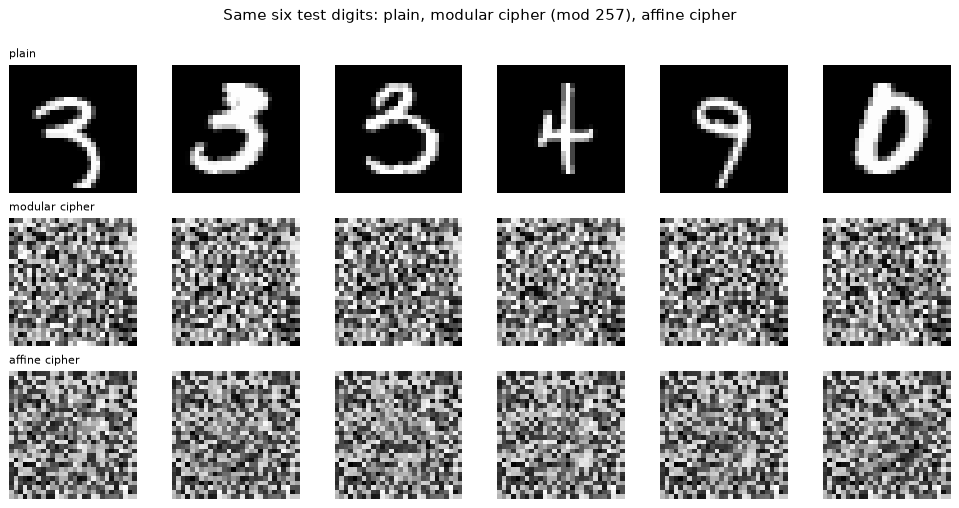

In [6]:
# ---- properties of the modular cipher, checked on real MNIST images ----
cm = Cipher("modular", seed=123)
p = torch.tensor(Xte_u8[:50].reshape(50, -1), dtype=torch.float64)                   # integer grey levels 0..255
x64 = p / 127.5 - 1.0
c = cm.raw(x64)
assert torch.equal(cm.decrypt_levels(c), p), "decryption must give back the grey levels exactly"
print("1) decrypt(encrypt(image)) == image for 50 test images (exact):  OK")
# additive homomorphism: E(v1) + E(v2) - b == E(v1 + v2)  (mod 257)
v1, v2 = p[:25], p[25:]
lhs = torch.remainder(cm.raw(v1 / 127.5 - 1.0) + cm.raw(v2 / 127.5 - 1.0) - cm.b, Q_MOD)
rhs = torch.remainder(cm.a * (v1 + v2) + cm.b, Q_MOD)
circ_diff = torch.remainder(lhs - rhs + Q_MOD / 2, Q_MOD) - Q_MOD / 2            # difference on the circle Z_257 (avoids 0 / 257 wrap artefacts)
assert circ_diff.abs().max() < 1e-6, "additive homomorphism"
print("2) E(v1) + E(v2) - b == E(v1 + v2) mod 257 (additively homomorphic):  OK")
assert torch.equal(cm.raw(x64), cm.raw(x64)); print("3) deterministic: the same image always gives the same ciphertext (no randomness, NOT semantically secure)")
# the two-query key recovery
k_hat = recover_key(cm.raw, "modular")
assert torch.equal(k_hat.a, cm.a) and torch.equal(k_hat.b, cm.b)
print("4) chosen-plaintext key recovery: 2 queries recover all 2 x 784 key numbers exactly:  OK")
ca = Cipher("affine", seed=124); k_hat_a = recover_key(ca.raw, "affine")
assert torch.allclose(k_hat_a.a, ca.a) and torch.allclose(k_hat_a.b, ca.b); print("   same for the affine cipher:  OK")

fig, ax = plt.subplots(3, 6, figsize=(11, 5.6))
for j in range(6):
    xi = torch.tensor(Xte_u8[j].reshape(1, -1) / 127.5 - 1.0, dtype=torch.float32)
    for r_, (name, img) in enumerate([("plain", xi), ("modular cipher", cm(xi)), ("affine cipher", ca(xi))]):
        ax[r_, j].imshow(img.reshape(28, 28).numpy(), cmap="gray"); ax[r_, j].axis("off")
        if j == 0: ax[r_, j].set_title(name, loc="left", fontsize=9)
plt.suptitle("Same six test digits: plain, modular cipher (mod 257), affine cipher", y=1.0); plt.tight_layout(); plt.show()

## 3. The GSW scheme the paper names, and why a network cannot train on it

The paper's scheme is GSW (Gentry-Sahai-Waters 2013): an LWE-based, fully homomorphic scheme whose ciphertext of **one bit** is an `N x N` matrix over Z_q. Here a toy version is implemented
(`n = 4`, `q = 2^60`, noise in {-1, 0, 1}; **not secure**, only to show the mechanics). Homomorphic addition is matrix addition, multiplication is a matrix product followed by `Flatten`.
We check AND / XOR / NAND on ciphertexts and an encrypted 4-bit adder. Then we test the property that matters for this paper: a *randomised* ciphertext carries no learnable information,
so a classifier (and hence a network) trained on it cannot beat chance.

In [7]:
class GSW:
    """Toy GSW fully homomorphic scheme (Gentry-Sahai-Waters 2013) in the Brakerski-Vaikuntanathan matrix form used by Minelli (2018).
    Plaintext = one bit; ciphertext = an N x N matrix over Z_q, N = n*l, q = 2**l.  Parameters are TOY sized (no real security)."""
    def __init__(s, n=4, l=60, noise=1, seed=0):
        s.n, s.l, s.q, s.N = n, l, 2**l, n*l; s.m = s.N
        s.rng = np.random.default_rng(seed); r = s.rng
        t = r.integers(0, s.q, n-1)                                   # secret key
        A = r.integers(0, s.q, (s.m, n-1)); e = r.integers(-noise, noise+1, s.m)
        s.B = np.concatenate([((A @ t + e) % s.q)[:, None], (-A) % s.q], axis=1)    # public key B with B v = e (small)
        s.v = np.concatenate([[1], t]) % s.q
        s.p2v = np.array([(int(vi) * 2**j) % s.q for vi in s.v for j in range(l)], dtype=np.int64)
        s.pw = 2 ** np.arange(l, dtype=np.int64)
    def bitdecomp(s, M):
        M = M % s.q; r, k = M.shape; return ((M[:, :, None] >> np.arange(s.l)) & 1).reshape(r, k*s.l)
    def bitdecomp_inv(s, M):
        r, kl = M.shape; return (M.reshape(r, kl//s.l, s.l) * s.pw).sum(axis=2) % s.q
    def flatten(s, M): return s.bitdecomp(s.bitdecomp_inv(M))
    def enc(s, mu):                                                   # fresh random R each time -> randomised encryption
        R = s.rng.integers(0, 2, (s.N, s.m))
        return (mu * np.eye(s.N, dtype=np.int64) + s.bitdecomp((R @ s.B) % s.q)) % s.q
    def noise_and_bit(s, C):
        row = int((C[s.l-2] @ s.p2v) % s.q); row = row - s.q if row > s.q//2 else row
        mu = int(abs(row) > s.q//8); return mu, abs(row - mu * 2**(s.l-2))
    def dec(s, C): return s.noise_and_bit(C)[0]
    def add(s, C1, C2): return (C1 + C2) % s.q
    def mult(s, C1, C2): return s.flatten((C1 @ C2) % s.q)
    def xor(s, C1, C2): return (C1 + C2 - 2 * s.mult(C1, C2)) % s.q
    def nand(s, C1, C2): return (np.eye(s.N, dtype=np.int64) - s.mult(C1, C2)) % s.q

g = GSW(seed=SEED)
print(f"GSW toy parameters: n={g.n}, l={g.l}, q=2^{g.l}, ciphertext = {g.N} x {g.N} matrix = {g.N**2} integers per encrypted BIT")
rows = []
for a_, b_ in itertools.product((0, 1), repeat=2):
    Ca, Cb = g.enc(a_), g.enc(b_)
    r_ = dict(a=a_, b=b_, AND=g.dec(g.mult(Ca, Cb)), XOR=g.dec(g.xor(Ca, Cb)), NAND=g.dec(g.nand(Ca, Cb)))
    assert r_["AND"] == (a_ & b_) and r_["XOR"] == (a_ ^ b_) and r_["NAND"] == 1 - (a_ & b_)
    rows.append(r_)
print(pd.DataFrame(rows).to_string(index=False)); print("homomorphic AND / XOR / NAND on ciphertexts decrypt correctly: OK")
assert not np.array_equal(g.enc(1), g.enc(1)); print("two encryptions of the same bit differ (randomised): OK")

def enc_adder(xs, ys):                      # ripple-carry adder evaluated entirely on ciphertexts
    out, carry = [], g.enc(0)
    for a_, b_ in zip(xs, ys):
        axb = g.xor(a_, b_); s_ = g.xor(axb, carry); carry = g.xor(g.mult(a_, b_), g.mult(carry, axb)); out.append(s_)
    return out + [carry]
for x_, y_ in [(5, 9), (15, 15), (7, 8)]:
    S_ = enc_adder([g.enc((x_ >> i) & 1) for i in range(4)], [g.enc((y_ >> i) & 1) for i in range(4)])
    res = sum(g.dec(c_) << i for i, c_ in enumerate(S_)); worst = max(int(g.noise_and_bit(c_)[1]) for c_ in S_)
    assert res == x_ + y_
    print(f"encrypted 4-bit adder: {x_:2d} + {y_:2d} = {res:2d}   worst ciphertext noise {worst:.2e}  (decryption limit {2**(g.l-3):.2e})")

GSW toy parameters: n=4, l=60, q=2^60, ciphertext = 240 x 240 matrix = 57600 integers per encrypted BIT


 a  b  AND  XOR  NAND
 0  0    0    0     1
 0  1    0    1     1
 1  0    0    1     1
 1  1    1    0     0
homomorphic AND / XOR / NAND on ciphertexts decrypt correctly: OK
two encryptions of the same bit differ (randomised): OK


encrypted 4-bit adder:  5 +  9 = 14   worst ciphertext noise 4.42e+10  (decryption limit 1.44e+17)


encrypted 4-bit adder: 15 + 15 = 30   worst ciphertext noise 4.49e+09  (decryption limit 1.44e+17)


encrypted 4-bit adder:  7 +  8 = 15   worst ciphertext noise 1.07e+15  (decryption limit 1.44e+17)


In [8]:
# Can a classifier learn anything from raw GSW ciphertexts?  Distinguish Enc(0) from Enc(1) using all N*N matrix entries.
n_ct = 600 if FAST_MODE else 1500
bits = np.random.default_rng(SEED).integers(0, 2, n_ct)
Xct = np.stack([(g.enc(int(b_)).reshape(-1) / g.q).astype(np.float32) for b_ in bits])      # entries scaled to [0, 1)
h = n_ct * 2 // 3
clf = LogisticRegression(max_iter=300).fit(Xct[:h], bits[:h])
acc_ct = clf.score(Xct[h:], bits[h:])
print(f"Logistic regression on {g.N**2} ciphertext entries, train {h} / test {n_ct-h} ciphertexts: test accuracy {acc_ct:.3f}  (50% = chance)")
print("=> a fresh GSW ciphertext carries no learnable signal about its bit (as semantic security demands). A network cannot be")
print("   trained on GSW ciphertexts of pixels, so the paper's 'encrypted MNIST' must have been a deterministic, learnable map.")

Logistic regression on 57600 ciphertext entries, train 1000 / test 500 ciphertexts: test accuracy 0.506  (50% = chance)
=> a fresh GSW ciphertext carries no learnable signal about its bit (as semantic security demands). A network cannot be
   trained on GSW ciphertexts of pixels, so the paper's 'encrypted MNIST' must have been a deterministic, learnable map.


## Dataset Exploration and Visualisation

Everything in this section uses the **real** MNIST images and their **real** digit labels. No data is generated or relabelled. First the shape, the label values and the class distribution,
then a two-dimensional scatter of real observations coloured by ground-truth digit: the raw PCA coordinates (PCA fitted on the training split) and the same coordinates scaled to rotation angles
as the QNN front layer does at initialisation. Finally the same scatter for the encrypted images that are fed to the networks in trial 3.

### Class distribution and sample images

Dataset: MNIST (LeCun et al.), official train/test split; subsample drawn with fixed seeds
train images: (2000, 28, 28) | test images: (1000, 28, 28) | features: 784 pixels pixel_0 ... pixel_783 (28 x 28 grey levels 0-255)
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
 digit  train  test
     0    193   109
     1    226   106
     2    203   105
     3    193    97
     4    186    86
     5    170    95
     6    220    93
     7    220   108
     8    191   101
     9    198   100


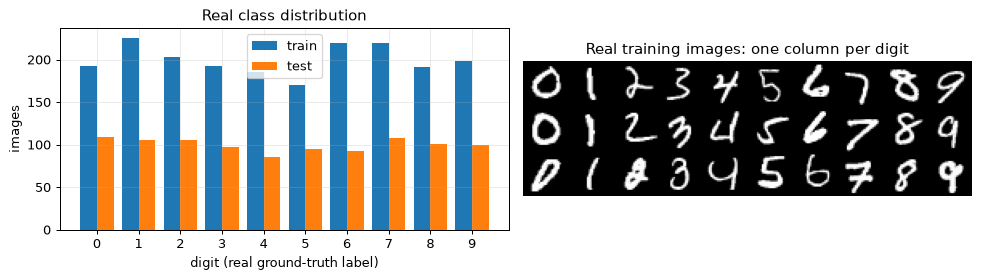

In [9]:
# ---- shape, feature names, labels --------------------------------------------------------------------
print("Dataset: MNIST (LeCun et al.), official train/test split; subsample drawn with fixed seeds")
print("train images:", Xtr_u8.shape, "| test images:", Xte_u8.shape, "| features: 784 pixels pixel_0 ... pixel_783 (28 x 28 grey levels 0-255)")
print("original label values:", DIGITS)
cnt = pd.DataFrame({"digit": DIGITS, "train": np.bincount(ytr_np, minlength=10), "test": np.bincount(yte_np, minlength=10)})
print(cnt.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
w_ = 0.4
ax[0].bar(np.arange(10) - w_/2, cnt["train"], w_, label="train"); ax[0].bar(np.arange(10) + w_/2, cnt["test"], w_, label="test")
ax[0].set_xticks(range(10)); ax[0].set_xlabel("digit (real ground-truth label)"); ax[0].set_ylabel("images"); ax[0].set_title("Real class distribution"); ax[0].legend()
grid = np.concatenate([np.concatenate([Xtr_u8[np.where(ytr_np == d)[0][k]] for d in DIGITS], axis=1) for k in range(3)], axis=0)
ax[1].imshow(grid, cmap="gray"); ax[1].axis("off"); ax[1].set_title("Real training images: one column per digit")
plt.tight_layout(); plt.show()

### Real observations in two dimensions, plain images

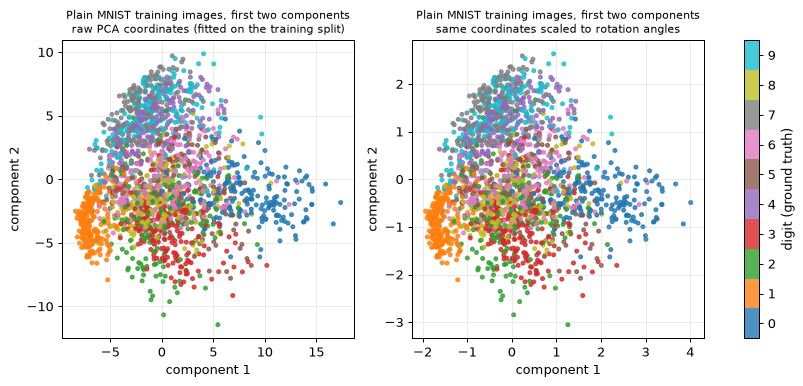

In [10]:
# ---- 2-D scatter of real observations coloured by ground-truth digit -------------------------------------------
def pca2(xa, xb=None, k=2):
    mu = xa.mean(0, keepdims=True); U_, S_, Vt = np.linalg.svd(xa - mu, full_matrices=False)
    z = (xa - mu) @ Vt[:k].T; sd = S_[:k] / np.sqrt(len(xa) - 1)
    return z, ((xb - mu) @ Vt[:k].T if xb is not None else None), sd

def scatter_pair(xa, ya, title, xb=None, yb=None):
    z, zb, sd = pca2(xa.numpy(), None if xb is None else xb.numpy())
    ang = np.pi * z / (3 * sd)                                  # the angle scaling used by the QNN front layer (pi / 3 sigma)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
    for k_, (pts, name) in enumerate([(z, "raw PCA coordinates (fitted on the training split)"), (ang, "same coordinates scaled to rotation angles")]):
        sc = ax[k_].scatter(pts[:, 0], pts[:, 1], c=ya.numpy(), cmap="tab10", s=9, alpha=0.8, vmin=-0.5, vmax=9.5)
        ax[k_].set_title(f"{title}\n{name}", fontsize=9); ax[k_].set_xlabel("component 1"); ax[k_].set_ylabel("component 2")
    cb = fig.colorbar(sc, ax=ax, ticks=range(10)); cb.set_label("digit (ground truth)")
    plt.show()

scatter_pair(xtr, ytr, "Plain MNIST training images, first two components")

### The same observations after the two encryption layers

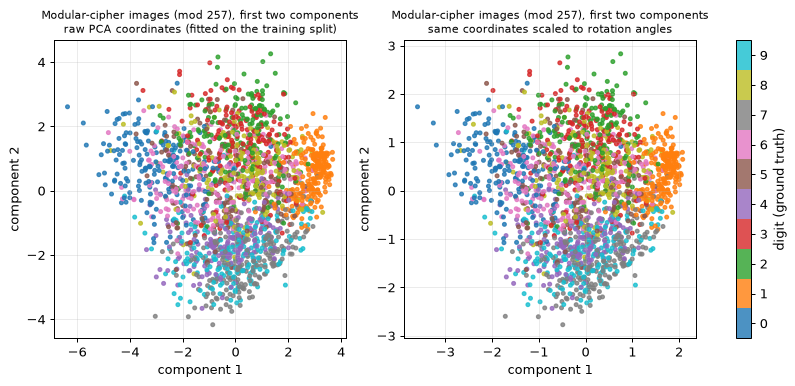

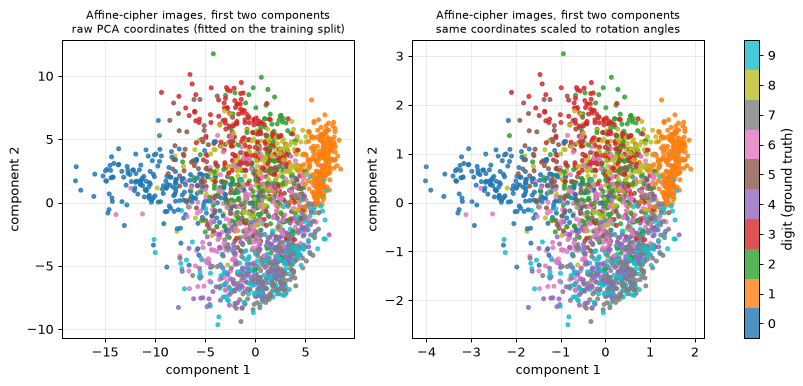

The plain digits already overlap in two components; the modular cipher scrambles pixel intensities non-linearly,
so the leading components of the encrypted images separate the digits much less.


In [11]:
# ---- the same real training images after the two encryption layers (a different key per layer) ---------------------
cm_view, ca_view = Cipher("modular", seed=5), Cipher("affine", seed=6)
scatter_pair(cm_view(xtr), ytr, "Modular-cipher images (mod 257), first two components")
scatter_pair(ca_view(xtr), ytr, "Affine-cipher images, first two components")
print("The plain digits already overlap in two components; the modular cipher scrambles pixel intensities non-linearly,")
print("so the leading components of the encrypted images separate the digits much less.")

## 4. Models and training

The **QNN** is a hybrid: a classical layer maps the 784 pixels to 8 rotation angles, `AngleEmbedding` loads them on 8 qubits, three `StronglyEntanglingLayers` (a general rotation on each qubit plus a ring of CNOTs per layer)
act on them, the 8 expectation values `<Z_i>` are read out and a small dense layer produces the 10 class scores. The classical layer is initialised with the PCA of the training images and then trained.
The circuit is a real PennyLane `QNode` (`circ`). Because the default PennyLane simulator is slow for hundreds of attack gradients, a batched torch simulator `sim_expz` applies **the same gate list**
(taken from the QNode's own tape) and is asserted equal to the QNode in the circuit section below; training and all attacks use `sim_expz`.

The **CNN** is the Keras `mnist_convnet` tutorial the paper cites, re-written in PyTorch.

In [12]:
# ---------------- the quantum circuit (PennyLane QNode) and an exact torch simulator that follows its gate list -----------------
dev = qml.device("default.qubit", wires=NQ)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def circ(angles, weights):
    qml.AngleEmbedding(angles, wires=range(NQ), rotation="X")            # paper: PennyLane angle embedding
    qml.StronglyEntanglingLayers(weights, wires=range(NQ))               # CHOICE: PennyLane template as the variational block
    return [qml.expval(qml.Z(i)) for i in range(NQ)]

_tape = qml.workflow.construct_batch(circ, level="device")(torch.zeros(NQ), torch.zeros(N_LAYERS, NQ, 3))[0][0]
GATES = [(o.name, tuple(o.wires)) for o in _tape.operations]             # gate list that the QNode really executes

def _perm(c, t):
    k = np.arange(2**NQ); return torch.tensor(np.where(((k >> (NQ-1-c)) & 1) == 1, k ^ (1 << (NQ-1-t)), k))
PERMS = {(l, i): _perm(i, (i + l % (NQ-1) + 1) % NQ) for l in range(N_LAYERS) for i in range(NQ)}   # CNOT(i, i+r) with r = l mod (n-1) + 1
ZS = {d: torch.tensor(np.array([[1 - 2*((k >> (NQ-1-i)) & 1) for i in range(NQ)] for k in range(2**NQ)]), dtype=d) for d in (torch.float32, torch.float64)}
def _rot(phi, theta, om):
    c, s = torch.cos(theta/2), torch.sin(theta/2); e = lambda a: torch.polar(torch.ones_like(a), a)
    return torch.stack([torch.stack([e(-(phi+om)/2)*c, -e((phi-om)/2)*s]), torch.stack([e(-(phi-om)/2)*s, e((phi+om)/2)*c])])

def sim_expz(angles, weights):
    """Batched exact state-vector simulation of `circ` (same gates, same order); returns <Z_i> for every qubit. Differentiable."""
    rd = angles.dtype; cd = torch.complex128 if rd == torch.float64 else torch.complex64
    B = angles.shape[0]; psi = torch.ones(B, 1, dtype=cd)
    for i in range(NQ):                                                   # RX(angle_i)|0> on every wire
        c = torch.cos(angles[:, i]/2).to(cd); s = (-1j * torch.sin(angles[:, i]/2)).to(cd)
        psi = (psi[:, :, None] * torch.stack([c, s], 1)[:, None, :]).reshape(B, -1)
    for l in range(N_LAYERS):
        for i in range(NQ):                                               # Rot(phi, theta, omega) on wire i
            U = _rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2]).to(cd)
            psi = torch.matmul(U, psi.reshape(B * 2**i, 2, 2**(NQ-i-1))).reshape(B, -1)
        for i in range(NQ): psi = psi[:, PERMS[(l, i)]]                   # CNOT ring
    return (psi.real**2 + psi.imag**2) @ ZS[rd]

class QNNNet(nn.Module):
    """Hybrid QNN: Linear(784 -> 8 angles) -> AngleEmbedding -> StronglyEntanglingLayers -> <Z_i> -> Linear(8 -> 10).
    CHOICE: the paper gives no architecture beyond 'angle embedding, QNode as Keras layer'; 784 pixels cannot be angle-encoded
    on 784 qubits, so a classical layer first reduces the image to 8 angles (initialised with PCA / 3 sigma scaling, then trained)."""
    def __init__(s, seed):
        super().__init__(); g_ = torch.Generator().manual_seed(seed)
        s.w = nn.Parameter(torch.randn(N_LAYERS, NQ, 3, generator=g_) * 0.5)
        s.front = nn.Linear(784, NQ); s.head = nn.Linear(NQ, 10)
        with torch.no_grad(): s.head.weight.copy_(torch.randn(10, NQ, generator=g_) * 0.5); s.head.bias.zero_()
    def fit_front(s, X):                                                   # PCA fitted on training data only
        mu = X.mean(0); _, S_, Vh = torch.linalg.svd(X - mu, full_matrices=False); sc = math.pi / (3 * S_[:NQ] / math.sqrt(len(X) - 1))
        with torch.no_grad(): s.front.weight.copy_(Vh[:NQ] * sc[:, None]); s.front.bias.copy_(-(mu @ Vh[:NQ].T) * sc)
    def angles(s, x): return s.front(x)
    def forward(s, x): return s.head(sim_expz(s.angles(x), s.w))

class CNNNet(nn.Module):                                                   # Keras mnist_convnet tutorial (Chollet), as cited by the paper
    def __init__(s, seed):
        super().__init__(); torch.manual_seed(seed)
        s.c1 = nn.Conv2d(1, 32, 3); s.c2 = nn.Conv2d(32, 64, 3); s.fc = nn.Linear(1600, 10); s.dp = nn.Dropout(0.5)
    def fit_front(s, X): pass
    def forward(s, x):
        x = x.reshape(-1, 1, 28, 28); x = F.max_pool2d(F.relu(s.c1(x)), 2); x = F.max_pool2d(F.relu(s.c2(x)), 2)
        return s.fc(s.dp(x.flatten(1)))

@torch.no_grad()
def predict(net, x, bs=500):
    net.eval(); return torch.cat([net(x[i:i+bs]) for i in range(0, len(x), bs)])
def accuracy(net, x, y): return (predict(net, x).argmax(1) == y).float().mean().item()

def train_model(family, seed, x, y, x_eval=None, y_eval=None, epochs=None):
    """Train from scratch.  Returns (net, history).  CHOICE: Adam + cross-entropy (the paper's SGD + MAE did not train in the budget, see section 10)."""
    epochs = epochs or EPOCHS; torch.manual_seed(seed)
    net = QNNNet(seed) if family == "QNN" else CNNNet(seed); net.fit_front(x)
    if family == "QNN":
        opt = torch.optim.Adam([{"params": [net.w] + list(net.head.parameters()), "lr": LR_QNN}, {"params": net.front.parameters(), "lr": LR_FRONT}])
    else:
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(seed); hist = []
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(x), generator=gen); tl = ta = 0.0
        for i in range(0, len(x), BATCH):
            idx = perm[i:i+BATCH]; opt.zero_grad(); out = net(x[idx]); loss = F.cross_entropy(out, y[idx]); loss.backward(); opt.step()
            tl += loss.item() * len(idx); ta += (out.argmax(1) == y[idx]).sum().item()
        h = dict(epoch=ep + 1, loss=tl / len(x), acc=ta / len(x))
        if x_eval is not None: net.eval(); h["val_acc"] = accuracy(net, x_eval, y_eval)
        hist.append(h)
    net.eval(); return net, hist

t0 = time.time(); _n, _h = train_model("QNN", 0, xtr[:256], ytr[:256], epochs=1); print(f"smoke test: one QNN epoch on 256 images {time.time()-t0:.1f}s, acc {_h[0]['acc']:.2f}")

smoke test: one QNN epoch on 256 images 5.6s, acc 0.10


## 5. Attacks

`fgsm` implements the paper's Eq. (2): `x_adv = x + eps * sign(grad_x J(theta, x, y))`. `pgd` is the iterated version (projected gradient descent in the L-infinity ball) used against
the adaptive cases. `make_f(net, cipher)` builds the deployed pipeline as a function of the **plain** image, with the encryption layer *inside* the differentiable function: that is exactly the white-box
attacker who knows the encryption.

In [13]:
def make_f(net, cipher=None):
    """The deployed pipeline as a function of the PLAIN image: (optional encryption layer) -> network. Differentiable end to end."""
    return (lambda x: net(cipher(x))) if cipher is not None else (lambda x: net(x))

def grad_sign(f, x, y):
    x = x.clone().requires_grad_(True); F.cross_entropy(f(x), y, reduction="sum").backward(); return x.grad.sign()

def fgsm(f, x, y, eps, clip, bs=100):
    out = []
    for i in range(0, len(x), bs):
        xb, yb = x[i:i+bs], y[i:i+bs]; xa = xb + eps * grad_sign(f, xb, yb)       # Eq. (2) of the paper: x_adv = x + eps * sign(grad_x J)
        out.append(xa.clamp(-1, 1) if clip else xa)
    return torch.cat(out).detach()

def pgd(f, x, y, eps, steps, clip=True, bs=100):
    out = []
    for i in range(0, len(x), bs):
        xb, yb = x[i:i+bs], y[i:i+bs]; xa = xb.clone(); alpha = 2.5 * eps / steps
        for _ in range(steps):
            xa = xa + alpha * grad_sign(f, xa, yb); xa = xb + (xa - xb).clamp(-eps, eps)
            if clip: xa = xa.clamp(-1, 1)
        out.append(xa.detach())
    return torch.cat(out)

def acc_f(f, x, y, bs=500):
    with torch.no_grad(): return float(np.mean(np.concatenate([(f(x[i:i+bs]).argmax(1) == y[i:i+bs]).numpy() for i in range(0, len(x), bs)])))

## 6. Experiment A: the paper's three trials

Exactly the paper's protocol: trial 1 trains on the original data (control). For trial 2 the FGSM examples are generated on the trial-1 model with the true labels, for the training **and** the test set,
and a new network is trained and validated on them. Trial 3 encrypts those attacked images (modular and affine cipher) and trains a new network on the ciphertext images.
Note that this is a *re-training on transformed data* protocol: it measures how learnable the transformed data are, not how robust a fixed deployed model is (that is experiment B).

In [14]:
# Paper protocol: trial 1 = original data (control); trial 2 = FGSM-attacked data; trial 3 = attacked data that is also encrypted.
# In every trial a NEW network is trained on the transformed training set and validated on the transformed test set.
resA, HIST, KEEP = [], {}, {}
t_all = time.time()
for family in ("QNN", "CNN"):
    eps = EPS_PAPER[family]
    for sd in SEEDS:
        t0 = time.time()
        net1, h1 = train_model(family, sd, xtr, ytr, xte, yte)                                    # trial 1: control
        f1 = make_f(net1)
        xa_tr, xa_te = fgsm(f1, xtr, ytr, eps, clip=False), fgsm(f1, xte, yte, eps, clip=False)    # attack generated on the control model, true labels
        net2, h2 = train_model(family, sd, xa_tr, ytr, xa_te, yte)                                # trial 2: attacked
        rows_ = [dict(family=family, seed=sd, trial="1 original (control)", acc=accuracy(net1, xte, yte), loss=h1[-1]["loss"]),
                 dict(family=family, seed=sd, trial="2 FGSM-attacked", acc=accuracy(net2, xa_te, yte), loss=h2[-1]["loss"])]
        HIST[(family, sd, "1")], HIST[(family, sd, "2")] = h1, h2
        for kind in CIPHER_KINDS:
            ck = Cipher(kind, seed=1000 + sd)
            net3, h3 = train_model(family, sd, ck(xa_tr), ytr, ck(xa_te), yte)                    # trial 3: attacked + encrypted
            rows_.append(dict(family=family, seed=sd, trial=f"3 attacked + encrypted ({kind})", acc=accuracy(net3, ck(xa_te), yte), loss=h3[-1]["loss"]))
            HIST[(family, sd, "3" + kind)] = h3
            if sd == SEEDS[0]: KEEP[(family, "enc_att_" + kind)] = (net3, ck)
        resA += rows_
        if sd == SEEDS[0]:
            KEEP[(family, "control")] = net1; KEEP[(family, "net2")] = net2; KEEP[(family, "data")] = (xa_tr, xa_te)
        print(f"{family} seed {sd}: " + " | ".join(f"{r_['trial'][:22]} {r_['acc']:.3f}" for r_ in rows_) + f"   ({time.time()-t0:.0f}s)")
dfA = pd.DataFrame(resA)
tabA = dfA.groupby(["family", "trial"], sort=False)["acc"].agg(["mean", "std", "count"]).round(4)
display(tabA); print(f"experiment A finished in {(time.time()-t_all)/60:.1f} min")

QNN seed 0: 1 original (control) 0.837 | 2 FGSM-attacked 0.104 | 3 attacked + encrypted 0.828 | 3 attacked + encrypted 0.100   (177s)


QNN seed 1: 1 original (control) 0.807 | 2 FGSM-attacked 0.115 | 3 attacked + encrypted 0.761 | 3 attacked + encrypted 0.105   (174s)


CNN seed 0: 1 original (control) 0.966 | 2 FGSM-attacked 0.998 | 3 attacked + encrypted 0.989 | 3 attacked + encrypted 0.970   (370s)


CNN seed 1: 1 original (control) 0.964 | 2 FGSM-attacked 0.999 | 3 attacked + encrypted 0.982 | 3 attacked + encrypted 0.979   (427s)


mean     std  count
family trial                                                  
QNN    1 original (control)              0.8220  0.0212      2
       2 FGSM-attacked                   0.1095  0.0078      2
       3 attacked + encrypted (modular)  0.7945  0.0474      2
       3 attacked + encrypted (affine)   0.1025  0.0035      2
CNN    1 original (control)              0.9650  0.0014      2
       2 FGSM-attacked                   0.9985  0.0007      2
       3 attacked + encrypted (modular)  0.9855  0.0049      2
       3 attacked + encrypted (affine)   0.9745  0.0064      2

experiment A finished in 19.2 min


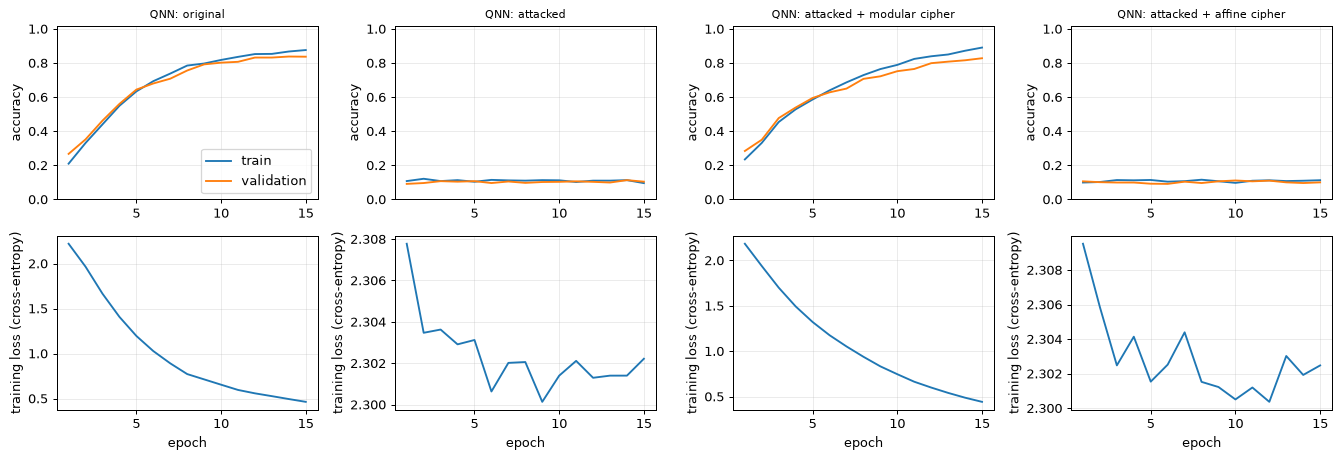

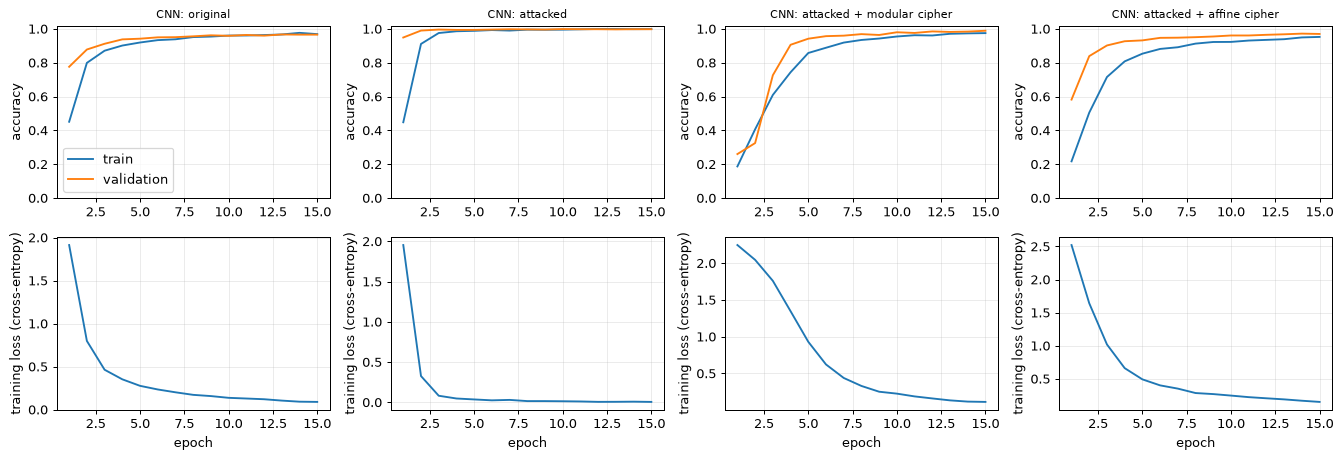

In [15]:
# Re-draw of the paper's Figures 4-9: training (blue) and validation (orange) accuracy / loss per epoch, first seed.
for family in ("QNN", "CNN"):
    keys = [("1", "original"), ("2", "attacked"), ("3modular", "attacked + modular cipher"), ("3affine", "attacked + affine cipher")]
    fig, ax = plt.subplots(2, 4, figsize=(15, 5.2))
    for j, (k_, name) in enumerate(keys):
        h = pd.DataFrame(HIST[(family, SEEDS[0], k_)])
        ax[0, j].plot(h.epoch, h.acc, label="train", color="tab:blue"); ax[0, j].plot(h.epoch, h.val_acc, label="validation", color="tab:orange")
        ax[0, j].set_title(f"{family}: {name}", fontsize=9); ax[0, j].set_ylabel("accuracy"); ax[0, j].set_ylim(0, 1.02)
        ax[1, j].plot(h.epoch, h.loss, color="tab:blue"); ax[1, j].set_ylabel("training loss (cross-entropy)"); ax[1, j].set_xlabel("epoch")
    ax[0, 0].legend(); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The circuit below is the one that is executed (PennyLane QNode `circ`), drawn with `qml.draw_mpl` for the trained weights and one real test image, once for the plain pipeline and once for the pipeline with the
encryption layer in front. The encryption layer is classical and acts on the pixels before the angle layer, so the **quantum circuit architecture is identical**; only the angles it receives (and the trained weights) differ.
A diagram shows where the layer sits. The cell then prints qubits, depth and trainable parameters, and asserts that the torch simulator used everywhere else equals the QNode (expectation values and gradients, float64).

*Assumptions where the paper omits circuit details:* 8 qubits; RX angle embedding (PennyLane default rotation); three StronglyEntanglingLayers with PennyLane's default CNOT ranges; read-out `<Z_i>` on every qubit; no noise, exact simulation.

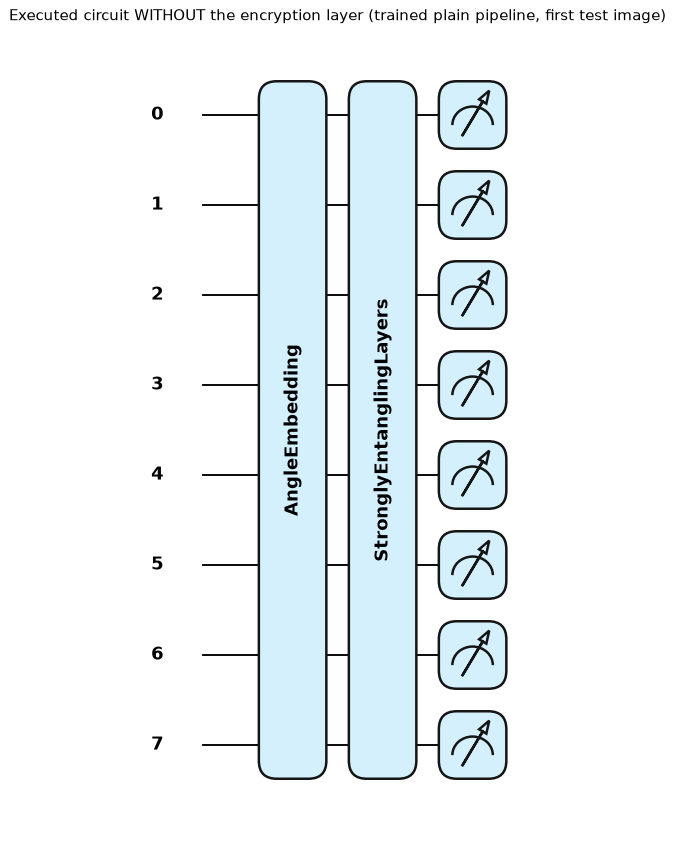

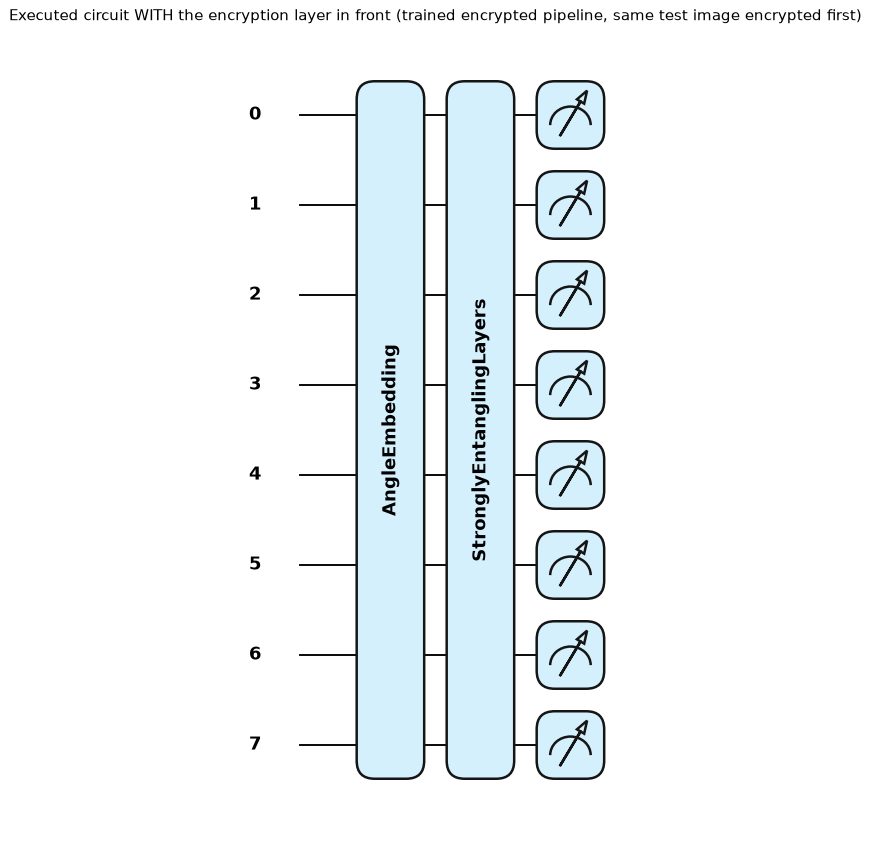

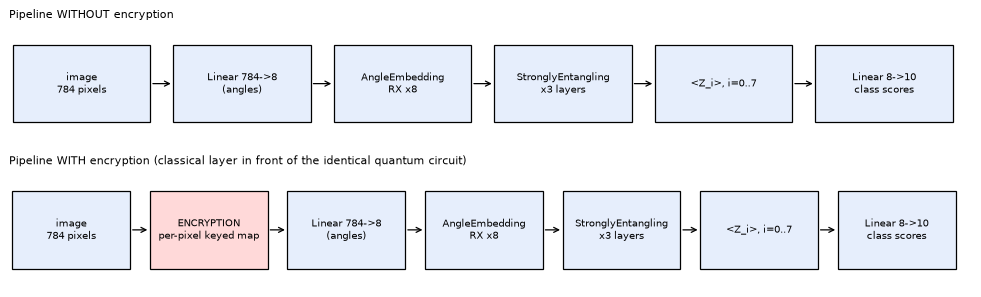

qubits: 8 | gates executed: 56 {'RX': 8, 'Rot': 24, 'CNOT': 24} | circuit depth: 19
trainable parameters: circuit 72 (3 rotation angles x 8 qubits x 3 layers) + classical front layer 6280 + head 90 = 6442
PennyLane specs: Wire allocations: 8
Total gates: 56
Gate counts:
- RX: 8
- Rot: 24
- CNOT: 24
Measurements:
- expval(PauliZ): 8
Depth: 19


plain pipeline: max |<Z>_QNode - <Z>_simulator| = 1.78e-15, max |gradient difference| = 6.48e-14


encrypted pipeline: max |<Z>_QNode - <Z>_simulator| = 1.22e-15, max |gradient difference| = 1.07e-13
gate list identical and exact simulator == PennyLane QNode (values and gradients): OK. Both pipelines run the SAME circuit; only the angles it receives differ.


In [16]:
from collections import Counter
net_pl = KEEP[("QNN", "control")]; net_en, ck_en = KEEP[("QNN", "enc_att_modular")]       # trained plain pipeline / trained encrypted pipeline (seed 0)
x0 = xte[:1]
a_pl = net_pl.angles(x0).detach()[0]; a_en = net_en.angles(ck_en(x0)).detach()[0]

# ---- the circuit that is executed, drawn from the real QNode with the trained weights ----
fig, _ = qml.draw_mpl(circ, decimals=2, style="pennylane")(a_pl, net_pl.w.detach())
fig.suptitle("Executed circuit WITHOUT the encryption layer (trained plain pipeline, first test image)", y=1.02); plt.show()
fig, _ = qml.draw_mpl(circ, decimals=2, style="pennylane")(a_en, net_en.w.detach())
fig.suptitle("Executed circuit WITH the encryption layer in front (trained encrypted pipeline, same test image encrypted first)", y=1.02); plt.show()

# ---- pipeline diagram: where the encryption layer sits ----
fig, ax = plt.subplots(2, 1, figsize=(11, 3.4));
def boxes(a, labels, title, hl=None):
    a.set_xlim(0, len(labels) * 2.1); a.set_ylim(0, 1.2); a.axis("off"); a.set_title(title, loc="left", fontsize=9)
    for i, t in enumerate(labels):
        a.add_patch(plt.Rectangle((i * 2.1 + 0.05, 0.2), 1.8, 0.8, fc="#ffd9d9" if i == hl else "#e6eefc", ec="k"))
        a.text(i * 2.1 + 0.95, 0.6, t, ha="center", va="center", fontsize=8)
        if i < len(labels) - 1: a.annotate("", xy=((i + 1) * 2.1 + 0.05, 0.6), xytext=(i * 2.1 + 1.85, 0.6), arrowprops=dict(arrowstyle="->"))
boxes(ax[0], ["image\n784 pixels", "Linear 784->8\n(angles)", "AngleEmbedding\nRX x8", "StronglyEntangling\nx3 layers", "<Z_i>, i=0..7", "Linear 8->10\nclass scores"], "Pipeline WITHOUT encryption")
boxes(ax[1], ["image\n784 pixels", "ENCRYPTION\nper-pixel keyed map", "Linear 784->8\n(angles)", "AngleEmbedding\nRX x8", "StronglyEntangling\nx3 layers", "<Z_i>, i=0..7", "Linear 8->10\nclass scores"], "Pipeline WITH encryption (classical layer in front of the identical quantum circuit)", hl=1)
plt.tight_layout(); plt.show()

# ---- resources: qubits, depth, trainable parameters ----
def depth_of(gates):
    free = [0] * NQ
    for _, wires in gates:
        t = 1 + max(free[w] for w in wires)
        for w in wires: free[w] = t
    return max(free)
n_circ = int(net_pl.w.numel()); n_front = sum(p.numel() for p in net_pl.front.parameters()); n_head = sum(p.numel() for p in net_pl.head.parameters())
print(f"qubits: {NQ} | gates executed: {len(GATES)} {dict(Counter(n for n, _ in GATES))} | circuit depth: {depth_of(GATES)}")
print(f"trainable parameters: circuit {n_circ} (3 rotation angles x {NQ} qubits x {N_LAYERS} layers) + classical front layer {n_front} + head {n_head} = {n_circ + n_front + n_head}")
try:
    sp = qml.specs(circ, level="device")(a_pl, net_pl.w.detach()); print("PennyLane specs:", sp["resources"])
except Exception as err:
    print("qml.specs not available in this form:", type(err).__name__)

# ---- equivalence: the fast torch simulator used for training/attacks == the real PennyLane QNode ----
expected = [("RX", (i,)) for i in range(NQ)]
for l in range(N_LAYERS):
    expected += [("Rot", (i,)) for i in range(NQ)]; r_ = l % (NQ - 1) + 1; expected += [("CNOT", (i, (i + r_) % NQ)) for i in range(NQ)]
assert GATES == expected, "gate list of the QNode differs from the gate list the simulator applies"
for name, net, ck in [("plain pipeline", net_pl, None), ("encrypted pipeline", net_en, ck_en)]:
    xs = xte[:32]; a64 = net.angles(ck(xs) if ck is not None else xs).detach().double(); w64 = net.w.detach().double().requires_grad_(True)
    e_q = torch.stack(circ(a64, w64), 1); e_s = sim_expz(a64, w64)
    g_q = torch.autograd.grad(e_q.sum(), w64)[0]; g_s = torch.autograd.grad(e_s.sum(), w64)[0]
    print(f"{name}: max |<Z>_QNode - <Z>_simulator| = {(e_q - e_s).abs().max():.2e}, max |gradient difference| = {(g_q - g_s).abs().max():.2e}")
    assert (e_q - e_s).abs().max() < 1e-9 and (g_q - g_s).abs().max() < 1e-9
print("gate list identical and exact simulator == PennyLane QNode (values and gradients): OK. Both pipelines run the SAME circuit; only the angles it receives differ.")

## 7. Does the FGSM data leak its label?

Equation (2) uses the **true label** y in the loss gradient. The perturbation `eps * sign(grad)` is therefore a function of y, and with epsilon 75 the perturbation dwarfs the image. If a network is *retrained* on such data (the paper's protocol)
it can read the label off the perturbation. Test: fit a logistic regression on the perturbation alone (no image information at all) and see how well it predicts the digit. The control uses perturbations computed with shuffled labels.

In [17]:
# Does an FGSM perturbation computed with the TRUE label leak the label?  Train a plain logistic regression on the perturbation alone.
rowsL = []
for family in ("QNN", "CNN"):
    net1 = KEEP[(family, "control")]; f1 = make_f(net1); eps = EPS_PAPER[family]
    d_tr_true = (fgsm(f1, xtr, ytr, eps, clip=False) - xtr) / eps; d_te_true = (fgsm(f1, xte, yte, eps, clip=False) - xte) / eps
    perm_lab = torch.tensor(np.random.default_rng(SEED).permutation(ytr_np))                 # control: gradient taken w.r.t. WRONG (shuffled) labels
    d_tr_shuf = (fgsm(f1, xtr, perm_lab, eps, clip=False) - xtr) / eps
    d_te_shuf = (fgsm(f1, xte, torch.tensor(np.random.default_rng(SEED + 1).permutation(yte_np)), eps, clip=False) - xte) / eps
    for name, dtr, dte in [("perturbation made with true labels", d_tr_true, d_te_true), ("perturbation made with shuffled labels (control)", d_tr_shuf, d_te_shuf)]:
        clf = LogisticRegression(max_iter=300).fit(dtr.numpy(), ytr_np)
        rowsL.append(dict(family=family, perturbation=name, label_accuracy_from_perturbation_only=round(clf.score(dte.numpy(), yte_np), 3)))
display(pd.DataFrame(rowsL)); print("chance level = 0.10")

,family,perturbation,label_accuracy_from_perturbation_only
0,QNN,perturbation made with true labels,0.713
1,QNN,perturbation made with shuffled labels (control),0.313
2,CNN,perturbation made with true labels,1.000
3,CNN,perturbation made with shuffled labels (control),0.622


chance level = 0.10


## 8. Experiment B: a deployed model, an evasion attacker, and adaptive attacks

A fixed model is trained on clean data (plain) or on encrypted clean data (the encryption layer is part of the deployed pipeline). The attacker perturbs **plain test images**:

* **no-encryption control**: white-box FGSM / PGD on the plain model;
* **oblivious**: the attacker crafts the example on the plain model (an upper bound for an attacker who ignores the encryption) and submits it to the encrypted pipeline;
* **key-aware**: gradients through the cipher (white-box adaptive attack);
* **chosen-plaintext key recovery**: two queries to the encryption oracle give the key; the key is checked equal to the true key and PGD is run through the recovered cipher;
* **key-less, distribution-aware**: the attacker knows the cipher family but not the key; it trains its own surrogate pipeline under its own random key on its own data and transfers the example.

Standard epsilons act on the (-1, 1) pixel scale and are clipped to the valid range. The paper-scale epsilons (6, 30, 75) are unclipped FGSM, as in the paper. Accuracies are on the first `N_ATT` test images (one seed).

In [18]:
# Evasion threat model: the defender's model is FIXED (trained on clean data, plain or through the encryption layer) and the attacker
# perturbs test inputs.  Attackers: white-box on the plain model (no-encryption control), oblivious (crafts on the plain model, does not know about
# the encryption), key-aware white-box (differentiates through the cipher), chosen-plaintext key recovery, and a key-less distribution-aware attacker
# (knows the cipher family, trains its own surrogate under its own random key on its own data, transfers the example).
t0 = time.time(); SD = SEEDS[0]; xat_n, yat_n = xat, yat
xe, ye = xte[:N_ATT], yte[:N_ATT]
rowsB, MB = [], {}
def rec(family, pipeline, attack, eps, clipped, acc): rowsB.append(dict(family=family, pipeline=pipeline, attack=attack, eps=eps, clipped=clipped, acc=acc))

for family in ("QNN", "CNN"):
    net_plain = KEEP[(family, "control")]; f_plain = make_f(net_plain)
    rec(family, "plain (no encryption)", "none", 0.0, True, acc_f(f_plain, xe, ye))
    for eps in EPS_STD:
        rec(family, "plain (no encryption)", "FGSM white-box", eps, True, acc_f(f_plain, fgsm(f_plain, xe, ye, eps, True), ye))
        rec(family, "plain (no encryption)", "PGD white-box", eps, True, acc_f(f_plain, pgd(f_plain, xe, ye, eps, PGD_STEPS, True), ye))
    for eps in EPS_LARGE: rec(family, "plain (no encryption)", "FGSM white-box", eps, False, acc_f(f_plain, fgsm(f_plain, xe, ye, eps, False), ye))
    for kind in CIPHER_KINDS:
        ckD = Cipher(kind, seed=3000 + SD)                                                  # defender's secret key
        net_enc, _ = train_model(family, SD, ckD(xtr), ytr); f_enc = make_f(net_enc, ckD); pipe = f"encrypted ({kind})"
        MB[(family, kind)] = (net_enc, ckD)
        rec(family, pipe, "none", 0.0, True, acc_f(f_enc, xe, ye))
        # attacker with chosen-plaintext access to the encryption oracle: two queries
        ck_hat = recover_key(ckD.raw, kind)
        assert torch.allclose(ck_hat.a, ckD.a) and torch.allclose(ck_hat.b, ckD.b)
        # key-less distribution-aware attacker: own key, own data, own surrogate pipeline
        ckA = Cipher(kind, seed=9000 + SD); net_sur, _ = train_model(family, SD + 50, ckA(xat), yat); f_sur = make_f(net_sur, ckA)
        for eps in EPS_STD:
            rec(family, pipe, "oblivious FGSM (crafted on plain model)", eps, True, acc_f(f_enc, fgsm(f_plain, xe, ye, eps, True), ye))
            rec(family, pipe, "oblivious PGD (crafted on plain model)", eps, True, acc_f(f_enc, pgd(f_plain, xe, ye, eps, PGD_STEPS, True), ye))
            rec(family, pipe, "key-less adaptive PGD (own key + surrogate)", eps, True, acc_f(f_enc, pgd(f_sur, xe, ye, eps, PGD_STEPS, True), ye))
            rec(family, pipe, "key-aware FGSM (through the cipher)", eps, True, acc_f(f_enc, fgsm(f_enc, xe, ye, eps, True), ye))
            rec(family, pipe, "key-aware PGD (through the cipher)", eps, True, acc_f(f_enc, pgd(f_enc, xe, ye, eps, PGD_STEPS, True), ye))
            rec(family, pipe, "chosen-plaintext key recovery + PGD", eps, True, acc_f(f_enc, pgd(make_f(net_enc, ck_hat), xe, ye, eps, PGD_STEPS, True), ye))
        for eps in EPS_LARGE:
            rec(family, pipe, "oblivious FGSM (crafted on plain model)", eps, False, acc_f(f_enc, fgsm(f_plain, xe, ye, eps, False), ye))
            rec(family, pipe, "key-aware FGSM (through the cipher)", eps, False, acc_f(f_enc, fgsm(f_enc, xe, ye, eps, False), ye))
    print(f"{family} done ({time.time()-t0:.0f}s)")
dfB = pd.DataFrame(rowsB)
pd.set_option("display.width", 220, "display.max_rows", 400)
for family in ("QNN", "CNN"):
    d = dfB[(dfB.family == family) & dfB.clipped]
    display(d.pivot_table(index=["pipeline", "attack"], columns="eps", values="acc", sort=False).round(3))
    d = dfB[(dfB.family == family) & ~dfB.clipped]
    display(d.pivot_table(index=["pipeline", "attack"], columns="eps", values="acc", sort=False).round(3))
print(f"experiment B finished in {(time.time()-t0)/60:.1f} min")

QNN done (348s)


CNN done (1144s)


eps                                                                 0.00   0.05   0.10   0.20
pipeline              attack                                                                 
plain (no encryption) none                                         0.835    NaN    NaN    NaN
                      FGSM white-box                                 NaN  0.710  0.525  0.265
                      PGD white-box                                  NaN  0.705  0.500  0.160
encrypted (modular)   none                                         0.660    NaN    NaN    NaN
                      oblivious FGSM (crafted on plain model)        NaN  0.130  0.140  0.100
                      oblivious PGD (crafted on plain model)         NaN  0.130  0.155  0.135
                      key-less adaptive PGD (own key + surrogate)    NaN  0.165  0.140  0.135
                      key-aware FGSM (through the cipher)            NaN  0.290  0.255  0.225
                      key-aware PGD (through the cipher)             NaN  0.200  0.160  0.170
                      chosen-plaintext key recovery + PGD            NaN  0.200  0.160  0.170
encrypted (affine)    none                                         0.820    NaN    NaN    NaN
                      oblivious FGSM (crafted on plain model)        NaN  0.770  0.710  0.530
                      oblivious PGD (crafted on plain model)         NaN  0.765  0.700  0.510
                      key-less adaptive PGD (own key + surrogate)    NaN  0.780  0.740  0.655
                      key-aware FGSM (through the cipher)            NaN  0.705  0.540  0.285
                      key-aware PGD (through the cipher)             NaN  0.695  0.510  0.160
                      chosen-plaintext key recovery + PGD            NaN  0.695  0.510  0.160

eps                                                             6.0    30.0   75.0
pipeline              attack                                                      
plain (no encryption) FGSM white-box                           0.140  0.100  0.095
encrypted (modular)   oblivious FGSM (crafted on plain model)  0.075  0.105  0.055
                      key-aware FGSM (through the cipher)      0.085  0.060  0.080
encrypted (affine)    oblivious FGSM (crafted on plain model)  0.110  0.090  0.105
                      key-aware FGSM (through the cipher)      0.090  0.075  0.090

eps                                                                 0.00   0.05   0.10   0.20
pipeline              attack                                                                 
plain (no encryption) none                                         0.980    NaN    NaN    NaN
                      FGSM white-box                                 NaN  0.965  0.925  0.835
                      PGD white-box                                  NaN  0.965  0.925  0.795
encrypted (modular)   none                                         0.795    NaN    NaN    NaN
                      oblivious FGSM (crafted on plain model)        NaN  0.135  0.120  0.145
                      oblivious PGD (crafted on plain model)         NaN  0.145  0.120  0.110
                      key-less adaptive PGD (own key + surrogate)    NaN  0.200  0.175  0.150
                      key-aware FGSM (through the cipher)            NaN  0.330  0.200  0.210
                      key-aware PGD (through the cipher)             NaN  0.210  0.165  0.215
                      chosen-plaintext key recovery + PGD            NaN  0.210  0.165  0.215
encrypted (affine)    none                                         0.940    NaN    NaN    NaN
                      oblivious FGSM (crafted on plain model)        NaN  0.910  0.880  0.835
                      oblivious PGD (crafted on plain model)         NaN  0.910  0.880  0.830
                      key-less adaptive PGD (own key + surrogate)    NaN  0.915  0.885  0.845
                      key-aware FGSM (through the cipher)            NaN  0.835  0.750  0.400
                      key-aware PGD (through the cipher)             NaN  0.835  0.735  0.315
                      chosen-plaintext key recovery + PGD            NaN  0.835  0.735  0.315

eps                                                             6.0    30.0   75.0
pipeline              attack                                                      
plain (no encryption) FGSM white-box                           0.000  0.000  0.000
encrypted (modular)   oblivious FGSM (crafted on plain model)  0.125  0.090  0.115
                      key-aware FGSM (through the cipher)      0.115  0.115  0.120
encrypted (affine)    oblivious FGSM (crafted on plain model)  0.005  0.005  0.005
                      key-aware FGSM (through the cipher)      0.000  0.000  0.000

experiment B finished in 19.1 min


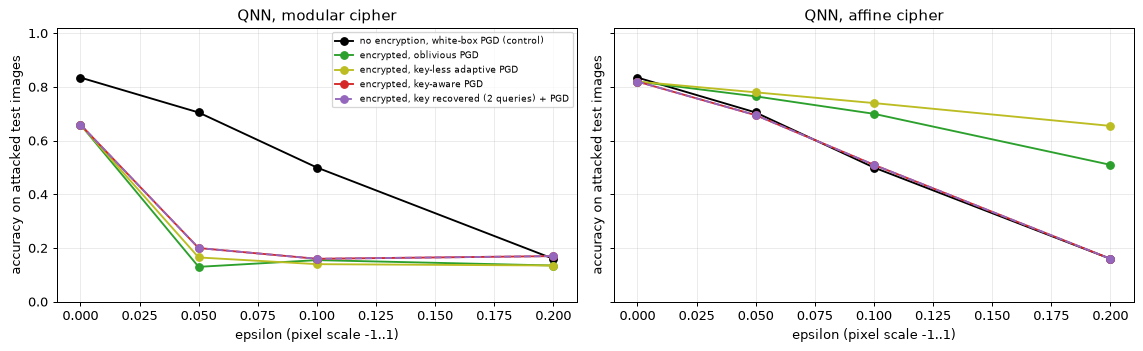

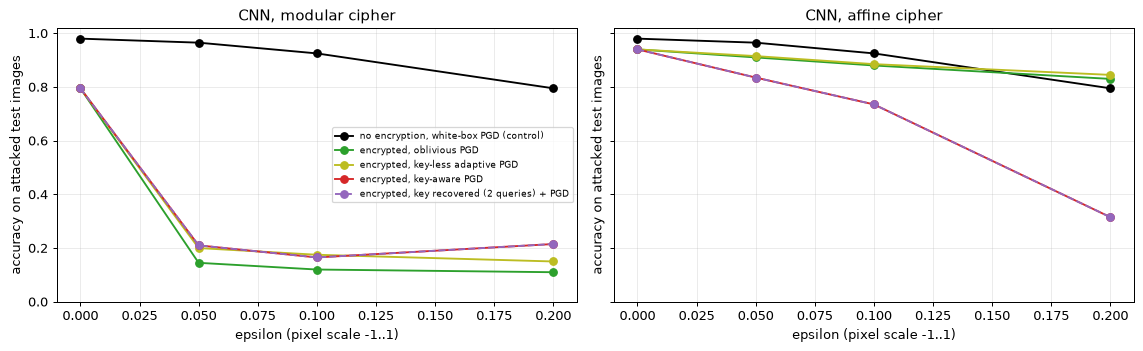

In [19]:
for family in ("QNN", "CNN"):
    fig, ax = plt.subplots(1, len(CIPHER_KINDS), figsize=(6.4 * len(CIPHER_KINDS), 4), sharey=True)
    for a_, kind in zip(np.atleast_1d(ax), CIPHER_KINDS):
        d0 = dfB[(dfB.family == family) & dfB.clipped]
        def curve(pipeline, attack, **kw):
            d = d0[(d0.pipeline == pipeline) & (d0.attack == attack)].sort_values("eps")
            c0 = d0[(d0.pipeline == pipeline) & (d0.attack == "none")].acc.iloc[0]
            a_.plot([0] + list(d.eps), [c0] + list(d.acc), marker="o", **kw)
        curve("plain (no encryption)", "PGD white-box", label="no encryption, white-box PGD (control)", color="k")
        pipe = f"encrypted ({kind})"
        curve(pipe, "oblivious PGD (crafted on plain model)", label="encrypted, oblivious PGD", color="tab:green")
        curve(pipe, "key-less adaptive PGD (own key + surrogate)", label="encrypted, key-less adaptive PGD", color="tab:olive")
        curve(pipe, "key-aware PGD (through the cipher)", label="encrypted, key-aware PGD", color="tab:red")
        curve(pipe, "chosen-plaintext key recovery + PGD", label="encrypted, key recovered (2 queries) + PGD", color="tab:purple", linestyle="--")
        a_.set_title(f"{family}, {kind} cipher"); a_.set_xlabel("epsilon (pixel scale -1..1)"); a_.set_ylabel("accuracy on attacked test images"); a_.set_ylim(0, 1.02)
    np.atleast_1d(ax)[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 9. Paper-literal optimiser check

The paper trains with plain SGD and the mean absolute error. The same hybrid network, the same data and the same number of epochs with exactly that optimiser and loss:

In [20]:
# The paper trains the QNN with plain SGD and the mean absolute error.  Same hybrid architecture, same data, same epochs, paper-literal optimiser/loss:
def mae_softmax(logits, y): return (F.softmax(logits, 1) - F.one_hot(y, 10).float()).abs().mean()          # Keras 'mean_absolute_error' on the softmax outputs
torch.manual_seed(0); net_lit = QNNNet(0); net_lit.fit_front(xtr)
opt = torch.optim.SGD(net_lit.parameters(), lr=0.1); gen = torch.Generator().manual_seed(0)
for ep in range(EPOCHS):
    perm = torch.randperm(len(xtr), generator=gen)
    for i in range(0, len(xtr), BATCH):
        idx = perm[i:i+BATCH]; opt.zero_grad(); mae_softmax(net_lit(xtr[idx]), ytr[idx]).backward(); opt.step()
acc_lit = accuracy(net_lit, xte, yte)
acc_adam = float(dfA[(dfA.family == "QNN") & dfA.trial.str.startswith("1")].acc.mean())
print(f"paper-literal SGD(lr 0.1) + MAE, {EPOCHS} epochs: test accuracy {acc_lit:.3f}   |   Adam + cross-entropy (used here): {acc_adam:.3f}")

paper-literal SGD(lr 0.1) + MAE, 15 epochs: test accuracy 0.185   |   Adam + cross-entropy (used here): 0.822


## 10. Classical baselines on identical inputs

The CNN of the paper is the classical benchmark (rows above). In addition an RBF support-vector machine and a random forest receive **the same 8 PCA angles** as the QNN (PCA fitted on each trial's own training set).

In [21]:
# Classical baselines on IDENTICAL inputs: the same 8 PCA angles the QNN receives (PCA fitted on each trial's own training set), plus the CNN above.
def angles_of(x_train, x_test):
    q = QNNNet(0); q.fit_front(x_train)
    with torch.no_grad(): return q.angles(x_train).numpy(), q.angles(x_test).numpy()
xa_tr, xa_te = KEEP[("QNN", "data")]; ck_m = KEEP[("QNN", "enc_att_modular")][1]; ck_a = KEEP[("QNN", "enc_att_affine")][1]
trials = {"1 original (control)": (xtr, xte), "2 FGSM-attacked": (xa_tr, xa_te),
          "3 attacked + encrypted (modular)": (ck_m(xa_tr), ck_m(xa_te)), "3 attacked + encrypted (affine)": (ck_a(xa_tr), ck_a(xa_te))}
rowsC = []
for name, (a_, b_) in trials.items():
    A_, B_ = angles_of(a_, b_)
    svc = SVC(kernel="rbf", C=1.0, random_state=SEED).fit(A_, ytr_np); rf = RandomForestClassifier(200, random_state=SEED, n_jobs=1).fit(A_, ytr_np)
    qnn_acc = dfA[(dfA.family == "QNN") & (dfA.trial == name) & (dfA.seed == SEEDS[0])].acc.iloc[0]
    cnn_acc = dfA[(dfA.family == "CNN") & (dfA.trial == name) & (dfA.seed == SEEDS[0])].acc.iloc[0]
    rowsC.append({"trial": name, "QNN (this notebook)": qnn_acc, "SVC rbf on the 8 angles": svc.score(B_, yte_np), "RandomForest on the 8 angles": rf.score(B_, yte_np), "CNN (28x28 pixels)": cnn_acc})
display(pd.DataFrame(rowsC).round(3))

,trial,QNN (this notebook),SVC rbf on the 8 angles,RandomForest on the 8 angles,CNN (28x28 pixels)
0,1 original (control),0.837,0.874,0.839,0.966
1,2 FGSM-attacked,0.104,0.776,0.758,0.998
2,3 attacked + encrypted (modular),0.828,0.778,0.750,0.989
3,3 attacked + encrypted (affine),0.100,0.772,0.755,0.970


## 11. Side by side with the paper, claim by claim

Verdict rule for numbers: "reproduced" if the notebook mean is within 0.02 of the paper's value, "exceeded" / "not reached" otherwise. Orderings are checked qualitatively. The adaptive-attack rows have no counterpart in the paper.

In [22]:
paper = {("QNN", "1 original (control)"): 0.9247, ("QNN", "2 FGSM-attacked"): 0.8406, ("QNN", "3 attacked + encrypted"): 0.9728,
         ("CNN", "1 original (control)"): 0.9926, ("CNN", "2 FGSM-attacked"): 0.7734, ("CNN", "3 attacked + encrypted"): 0.3814}
def mean_acc(family, prefix, kind=None):
    d = dfA[(dfA.family == family) & dfA.trial.str.startswith(prefix) & ((dfA.trial.str.contains(kind)) if kind else True)]
    return float(d.acc.mean())
def verdict_num(p, n, tol=0.02):
    return "reproduced" if abs(p - n) <= tol else ("exceeded" if n > p else "not reached")
rows = []
for (fam, tr), p in paper.items():
    for kind in (CIPHER_KINDS if tr.startswith("3") else [None]):
        n = mean_acc(fam, tr[0], kind)
        rows.append({"claim": f"{fam} accuracy, trial {tr}" + (f" [{kind} cipher]" if kind else ""), "paper": p, "notebook": round(n, 4),
                     "gap": round(n - p, 4), "verdict": verdict_num(p, n)})
q1, q2 = mean_acc("QNN", "1"), mean_acc("QNN", "2"); c1, c2 = mean_acc("CNN", "1"), mean_acc("CNN", "2")
for kind in CIPHER_KINDS:
    q3, c3 = mean_acc("QNN", "3", kind), mean_acc("CNN", "3", kind)
    rows.append({"claim": f"ordering: QNN encrypted+attacked > QNN control ({kind})", "paper": "yes (0.9728 > 0.9247)", "notebook": f"{q3:.3f} vs {q1:.3f}", "gap": "", "verdict": "reproduced" if q3 > q1 else "not reached"})
    rows.append({"claim": f"ordering: QNN encrypted+attacked > QNN attacked ({kind})", "paper": "yes (0.9728 > 0.8406)", "notebook": f"{q3:.3f} vs {q2:.3f}", "gap": "", "verdict": "reproduced" if q3 > q2 else "not reached"})
    rows.append({"claim": f"ordering: CNN encrypted < CNN attacked < CNN control ({kind})", "paper": "yes (0.3814 < 0.7734 < 0.9926)", "notebook": f"{c3:.3f} < {c2:.3f} < {c1:.3f}", "gap": "", "verdict": "reproduced" if c3 < c2 < c1 else "not reached"})
big = dfB[(dfB.family == "QNN") & (~dfB.clipped) & (dfB.pipeline == "plain (no encryption)") & (dfB.eps == 75.0)].acc.iloc[0]
rows.append({"claim": "QNN stays above 0.95 under FGSM with large epsilon (paper: up to eps 60; evasion setting, eps 75 here)", "paper": ">0.95", "notebook": round(big, 3), "gap": "", "verdict": "reproduced" if big > 0.95 else "not reached"})
for fam in ("QNN", "CNN"):
    for kind in CIPHER_KINDS:
        pipe = f"encrypted ({kind})"; e = 0.1
        d = dfB[(dfB.family == fam) & dfB.clipped & (dfB.eps == e)]
        plain = d[(d.pipeline == "plain (no encryption)") & (d.attack == "PGD white-box")].acc.iloc[0]
        obl = d[(d.pipeline == pipe) & (d.attack == "oblivious PGD (crafted on plain model)")].acc.iloc[0]
        key = d[(d.pipeline == pipe) & (d.attack == "key-aware PGD (through the cipher)")].acc.iloc[0]
        cpa = d[(d.pipeline == pipe) & (d.attack == "chosen-plaintext key recovery + PGD")].acc.iloc[0]
        clean = dfB[(dfB.family == fam) & (dfB.pipeline == pipe) & (dfB.attack == "none")].acc.iloc[0]
        rows.append({"claim": f"{fam}, {kind} cipher: encryption defends against an oblivious attacker (eps {e}, clean-encrypted acc {clean:.2f})", "paper": "defended", "notebook": f"{obl:.3f} (plain pipeline under PGD: {plain:.3f})", "gap": "", "verdict": "reproduced" if (obl > plain + 0.1 and obl >= 0.8 * clean) else "not reached"})
        rows.append({"claim": f"{fam}, {kind} cipher: encryption still defends against an ADAPTIVE (key-aware) attacker (eps {e})", "paper": "not tested", "notebook": f"{key:.3f} (key recovered by 2 queries: {cpa:.3f})", "gap": "", "verdict": "cannot be checked in the paper; here: " + ("defence holds" if (key > plain + 0.1 and key >= 0.8 * clean) else "defence broken")})
rows.append({"claim": "homomorphic encryption of the QNN itself / quantum supremacy statement", "paper": "future work / claimed", "notebook": "GSW cannot be evaluated by a network (section 3)", "gap": "", "verdict": "cannot be checked"})
V = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 140, "display.width", 250); display(V)

,claim,paper,notebook,gap,verdict
0,"QNN accuracy, trial 1 original (control)",0.9247,0.822,-0.1027,not reached
1,"QNN accuracy, trial 2 FGSM-attacked",0.8406,0.1095,-0.7311,not reached
2,"QNN accuracy, trial 3 attacked + encrypted [modular cipher]",0.9728,0.7945,-0.1783,not reached
3,"QNN accuracy, trial 3 attacked + encrypted [affine cipher]",0.9728,0.1025,-0.8703,not reached
4,"CNN accuracy, trial 1 original (control)",0.9926,0.965,-0.0276,not reached
5,"CNN accuracy, trial 2 FGSM-attacked",0.7734,0.9985,0.2251,exceeded
6,"CNN accuracy, trial 3 attacked + encrypted [modular cipher]",0.3814,0.9855,0.6041,exceeded
7,"CNN accuracy, trial 3 attacked + encrypted [affine cipher]",0.3814,0.9745,0.5931,exceeded
8,ordering: QNN encrypted+attacked > QNN control (modular),yes (0.9728 > 0.9247),0.794 vs 0.822,,not reached
9,ordering: QNN encrypted+attacked > QNN attacked (modular),yes (0.9728 > 0.8406),0.794 vs 0.110,,reproduced


## 12. Reading the paper critically

Numbers below are from the full run recorded in this notebook (2 seeds in experiment A, one seed and 200 attacked images in experiment B, so differences of a few points are noise).

1. **The three-trial protocol measures learnability, not robustness.** A new network is trained and tested on already-transformed data. Here the retrained CNN reaches 0.9985 on the FGSM data, *above* its 0.965 control, instead of the paper's 0.7734. Section 7 shows why such data cannot be read as an attack: a logistic regression that sees only the perturbation predicts the digit with accuracy 1.00 (CNN data) and 0.71 (QNN data), against 0.62 and 0.31 when the perturbation is computed with shuffled labels. The sign map carries the image shape in both cases, but the true label adds a large extra signal, because Eq. (2) uses it. The QNN, on the other hand, cannot learn from epsilon-75 data at all (0.11): the perturbation is far outside the 2 pi period of the angle embedding. Which unreported choice (clipping, the loss used for the gradient, the data the attack was generated from) produced the paper's 0.84 and 0.77 cannot be recovered from the text.
2. **The paper's headline ordering is only partly reproduced, and for a different reason.** Encrypted + attacked beats attacked for the QNN (0.79 vs 0.11 with the modular cipher), as in the paper, but it does not beat the control (0.82), and the affine cipher gives no gain (0.10). The cause is mechanical: the mod-257 wrap-around turns a +-75 perturbation into bounded ciphertext values the angle layer can handle. It is not security. The CNN trained on encrypted attacked data is at 0.99, not 0.38.
3. **Encryption is not an adversarial defence in a deployed-model setting.** With the cipher inside the pipeline, an oblivious attacker (crafting on the plain model, with epsilon 0.1) drops the modular-cipher QNN from 0.66 to 0.16 and the modular-cipher CNN from 0.80 to 0.12, i.e. *worse* than the unencrypted model under a white-box attack (0.50 and 0.93): the per-pixel multiplier turns a one-level change of a grey value into a large change of the ciphertext. The affine cipher is gentler but not protective (QNN 0.70 oblivious vs 0.51 key-aware vs 0.50 for the plain model). An attacker who queries the encryption oracle twice recovers the whole key (asserted equal to the true key) and the resulting PGD gives exactly the same numbers as the key-aware attacker, and a key-less attacker with its own surrogate is also effective. The 'defence' only works against an attacker that is both oblivious and lucky.
4. **QNN more robust than CNN?** Not here. At epsilon 0.1 (PGD, clipped) the plain QNN falls from 0.84 to 0.50, the plain CNN from 0.98 to 0.93. At the paper-scale epsilons (6, 30, 75; unclipped FGSM) the QNN is at 0.10-0.14, so the claim of more than 95 percent accuracy up to epsilon 60 is not reached. A periodic angle embedding makes huge perturbations wrap around; that is chaotic behaviour, not noise tolerance.
5. **Homomorphic encryption addresses privacy, not robustness.** A GSW ciphertext of one bit is a 240 x 240 matrix here, and a classifier on fresh ciphertexts is at chance (0.51), as semantic security requires. Therefore a network cannot have been trained on GSW ciphertexts of pixels, and the paper does not say what was fed to the network. Moreover, whoever perturbs the plaintext before encryption is unaffected by the encryption, and whoever perturbs the ciphertext only produces garbage on decryption. The paper itself says it could not encrypt the network.
6. **No quantum evidence.** Everything is an exact classical simulation; the hybrid QNN has 72 circuit parameters against 6,370 classical ones, and an RBF-SVM on the very same 8 angles reaches 0.87 versus 0.84 for the QNN. The paper's 'quantum supremacy' reading is not supported by these experiments.
7. **Limits of this reproduction.** Subsets of MNIST (2,000 training images), a self-designed 8-qubit hybrid, Adam with cross-entropy (the paper-literal SGD + MAE reached only 0.19 in the same budget), a PyTorch rewrite of the Keras CNN, deterministic keyed ciphers standing in for GSW.

## 13. Exercises

1. Replace the modular cipher by one with a fresh random key per image (a one-time pad). Why can no network be trained on it, and what must the model be given to still classify?
2. Re-run trial 2 with FGSM computed from the *predicted* label instead of the true label. Does the leakage test of section 7 still succeed?
3. Raise `N_LAYERS` or add data re-uploading to the circuit. Does the QNN clean accuracy approach the SVC of section 10 and does its robustness change?
4. Clip the paper-scale FGSM to the valid pixel range (`clip=True`). Which of the paper's conclusions survive?
5. Make the modular cipher non-bijective (for instance quantise pixels to 16 levels before encrypting). How do the clean accuracy and the key-recovery attack change?